# Training results
Losses of the DPR models trained on FiQA.

In [4]:
import json
import math
import os

import matplotlib.pyplot as plt

WEIGHTS_DIR = 'outputs/dpr_weights'
pools = ['cls', 'mean', 'max']
temperatures = [0.02, 0.05, 0.1]
chance = math.log(16)   # loss of a random model with batch size 16


def load(path):
    if not os.path.exists(path):
        print('Not found:', path)
        return None
    with open(path) as f:
        return json.load(f)


def train_per_epoch(r):
    steps = len(r['train_losses']) // r['epochs']
    return [sum(r['train_losses'][i*steps:(i+1)*steps]) / steps for i in range(r['epochs'])]


def plot_run(ax, r, title):
    epochs = range(1, r['epochs'] + 1)
    ax.plot(epochs, train_per_epoch(r), marker='o', label='train')
    ax.plot(epochs, r['val_losses'], marker='o', label='validation')
    ax.axvline(r['best_epoch'], linestyle='--', color='gray', label='best epoch')
    ax.axhline(chance, linestyle=':', color='black', label='random (ln 16)')
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.grid(alpha=0.3)

## Encoder from scratch: pooling

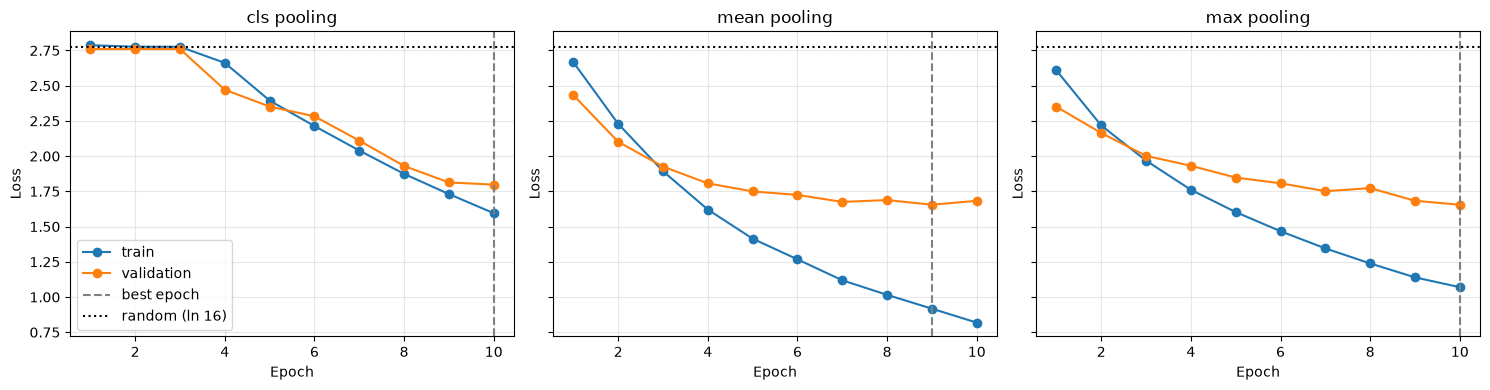

In [5]:
scratch = {p: load(f'{WEIGHTS_DIR}/{p}/losses_{p}.json') for p in pools}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, p in zip(axes, pools):
    if scratch[p]:
        plot_run(ax, scratch[p], f'{p} pooling')
axes[0].legend()
plt.tight_layout()
plt.show()

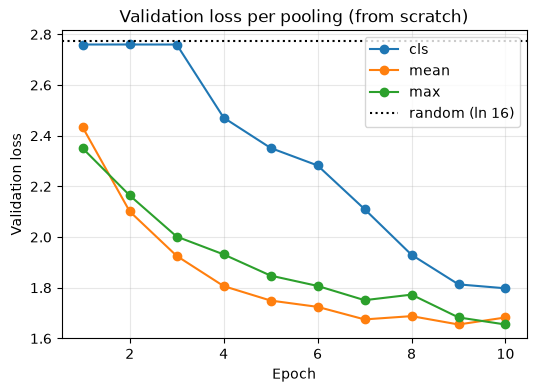

In [6]:
plt.figure(figsize=(6, 4))
for p in pools:
    if scratch[p]:
        plt.plot(range(1, scratch[p]['epochs'] + 1), scratch[p]['val_losses'], marker='o', label=p)
plt.axhline(chance, linestyle=':', color='black', label='random (ln 16)')
plt.title('Validation loss per pooling (from scratch)')
plt.xlabel('Epoch')
plt.ylabel('Validation loss')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Pretrained BERT (fine-tuned)

In [ ]:
bert = {p: load(f'{WEIGHTS_DIR}/bert_{p}/losses_bert_{p}.json') for p in pools}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, p in zip(axes, pools):
    if bert[p]:
        plot_run(ax, bert[p], f'BERT, {p} pooling')
axes[0].legend()
plt.tight_layout()
plt.show()

## From scratch vs. pretrained BERT
Best validation loss of each model.

In [ ]:
x = range(len(pools))
best_scratch = [min(scratch[p]['val_losses']) if scratch[p] else 0 for p in pools]
best_bert = [min(bert[p]['val_losses']) if bert[p] else 0 for p in pools]

plt.figure(figsize=(6, 4))
plt.bar([i - 0.2 for i in x], best_scratch, width=0.4, label='from scratch')
plt.bar([i + 0.2 for i in x], best_bert, width=0.4, label='pretrained BERT')
plt.axhline(chance, linestyle=':', color='black', label='random (ln 16)')
plt.xticks(x, pools)
plt.title('Best validation loss')
plt.xlabel('Pooling')
plt.ylabel('Validation loss')
plt.legend()
plt.show()

## Temperature (mean pooling)
The loss scale depends on the temperature, so these curves are not directly comparable: the final choice is made with recall on validation.

In [ ]:
temp = {t: load(f'{WEIGHTS_DIR}/temperature/mean_T{t}/losses_T{t}.json') for t in temperatures}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, t in zip(axes, temperatures):
    if temp[t]:
        plot_run(ax, temp[t], f'T = {t}')
axes[0].legend()
plt.tight_layout()
plt.show()

## Summary

In [7]:
runs = {f'scratch {p}': scratch[p] for p in pools}
runs.update({f'BERT {p}': bert[p] for p in pools})
runs.update({f'mean T={t}': temp[t] for t in temperatures})

print(f"{'model':<15}{'best epoch':>12}{'best val loss':>15}{'final train loss':>18}")
for name, r in runs.items():
    if r:
        print(f"{name:<15}{r['best_epoch']:>12}{min(r['val_losses']):>15.4f}{train_per_epoch(r)[-1]:>18.4f}")

NameError: name 'bert' is not defined